In [1]:
# Run this to install nGibbs! Then restart the kernel (and rerun the cells at the top that define the different compositions).
# Warning: it requires pytorch, which is a little large: ~300 MB for the CPU-only version.

# try: 
#     import nGibbs
# except ImportError:
#     ptt.install_nGibbs()

# --pre means pre-release! nGibbs is still in development.

In [2]:
import numpy as np # Numpy is used for math and stats in python 
import pandas as pd # Pandas is used for handling data in a spreadsheet like way
import matplotlib.pyplot as plt  # Matplotlib is used for plotting

In [3]:
# If the alphaMELTS for Python files have not been added to your Python path (see installation guide) then use the two lines below to add
# the location of the alphaMELTS files here.

# import sys
# sys.path.append(r'C:\Users\penny\Box\Berkeley_new\MELTS_Installation\alphamelts_py\alphamelts-py-2.3.1-win64')


import petthermotools as ptt 

print(ptt.__version__)

alphaMELTS for Python files successfully located.
If you are planning on using the Green et al. (2025) or Weller et al. (2024) thermodynamic models through MAGEMin for crystallization, melting, or phase diagram calculations
you will need to run `ptt.activate_petthermotools_env()` at the start of each notebook, prior to any calculations, every time you restart the kernel. 
This step establishes the python-julia connection and sets up the julia workers. Expect it to take about 20-40s on most machines.
1.3.4


If using Windows I'd recommend opening up 2 different notebooks. One in which to run the alphaMELTS calculations and one to run the MAGEMin calculations. The reason for this is due to the way that the julia workers are established on Windows machines, and how they interfere with the creation of new Python processes, significantly slowing down any MELTS calculations in a notebook where you are also running MAGEMin calculations. For MacOS users this is not a problem.

TLDR - if on Windows as soon as you run the `ptt.activate_petthermotools_env()` function this will enable calculations with MAGEMin (assuming the installation was created properly), but will restrict any alphaMELTS calculations.

In [4]:
### On Windows only run the following cell in the notebook where you intend to use the MAGEMin models
ptt.activate_petthermotools_env()

Initializing MAGEMin environment and workers...
Julia environment detected.
Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


  Activating project at `~/.petthermotools_julia_env`


Using libMAGEMin.dylib from MAGEMin_jll


  Activating project at `~/.petthermotools_julia_env`


      From worker 3:	  Activating project at `~/.petthermotools_julia_env`
      From worker 4:	  Activating project at `~/.petthermotools_julia_env`
      From worker 5:	  Activating project at `~/.petthermotools_julia_env`
      From worker 2:	  Activating project at `~/.petthermotools_julia_env`
      From worker 5:	Using libMAGEMin.dylib from MAGEMin_jll
      From worker 4:	Using libMAGEMin.dylib from MAGEMin_jll
      From worker 2:	Using libMAGEMin.dylib from MAGEMin_jll
      From worker 3:	Using libMAGEMin.dylib from MAGEMin_jll
Julia Environment and Workers Ready.


# Part 1 - Crystallization models

For this exercise we're going to start with a whole-rock composition of shield stage and post-shield stage basalts from the understudied volcano of Hualalai on the island of Hawai'i. This data is downloaded from GEOROC.

To start we'll run some simple crystallization models and compare the outputs from the rhyolite-MELTS v1.0.2 and Green et al. (2025) thermodynamic models.

In [5]:
### Post-shield basalt - data from Hanano et al. (2010)
postshield = {'SiO2_Liq': 46.74,
            'TiO2_Liq': 1.99,
            'Al2O3_Liq': 13.63,
            'Cr2O3_Liq': 0.0,
            'FeOt_Liq': 12.51,
            'MnO_Liq': 0.18,
            'MgO_Liq': 10.55,
            'CaO_Liq': 10.39,
            'Na2O_Liq': 2.76,
            'K2O_Liq': 0.81,
            'P2O5_Liq': 0.26,
            'H2O_Liq': 0.5}

In [6]:
### Post-shield basalt - data from Yokose et al. (2005)
shield = {'SiO2_Liq': 49.40,
        'TiO2_Liq': 1.83,
        'Al2O3_Liq': 12.00,
        'Cr2O3_Liq': 0.0,
        'FeOt_Liq': 10.80,
        'MnO_Liq': 0.17,
        'MgO_Liq': 12.40,
        'CaO_Liq': 9.55,
        'Na2O_Liq': 1.93,
        'K2O_Liq': 0.37,
        'P2O5_Liq': 0.21,
        'H2O_Liq': 0.2}

Let's start with the shield basalts. Run fractional crystallization calculations with the Green et al. (2025) thermodynamic model at a range of pressures, plot up the phase proportions and liquid line of descent (use the in-built plotting function).

Once you've completed this try running the same calculations with the rhyolite-MELTS v1.0.2 model (use a different notebook if working on a windows PC) and compare the results!

In [7]:
frac_green = ptt.isobaric_crystallisation(Model = "Green2025",
                                        bulk = shield,
                                        find_liquidus=True,
                                        Frac_solid = True,
                                        dt_C = 2,
                                        T_end_C = 1000,
                                        P_bar = [500,1000,2000,4000],
                                        fO2_buffer="FMQ",
                                        label = "P_bar")

A default timeout of 5 minutes has been specified. If you are not getting any results try increasing this using the timeout kwarg.


(<Figure size 960x900 with 9 Axes>,
 array([[<Axes: xlabel='MgO', ylabel='SiO$_2$'>,
         <Axes: xlabel='MgO', ylabel='TiO$_2$'>,
         <Axes: xlabel='MgO', ylabel='Al$_2$O$_3$'>],
        [<Axes: xlabel='MgO', ylabel='FeO$_t$'>,
         <Axes: xlabel='MgO', ylabel='CaO'>,
         <Axes: xlabel='MgO', ylabel='Na$_2$O'>],
        [<Axes: xlabel='MgO', ylabel='K$_2$O'>, <Axes: >, <Axes: >]],
       dtype=object))

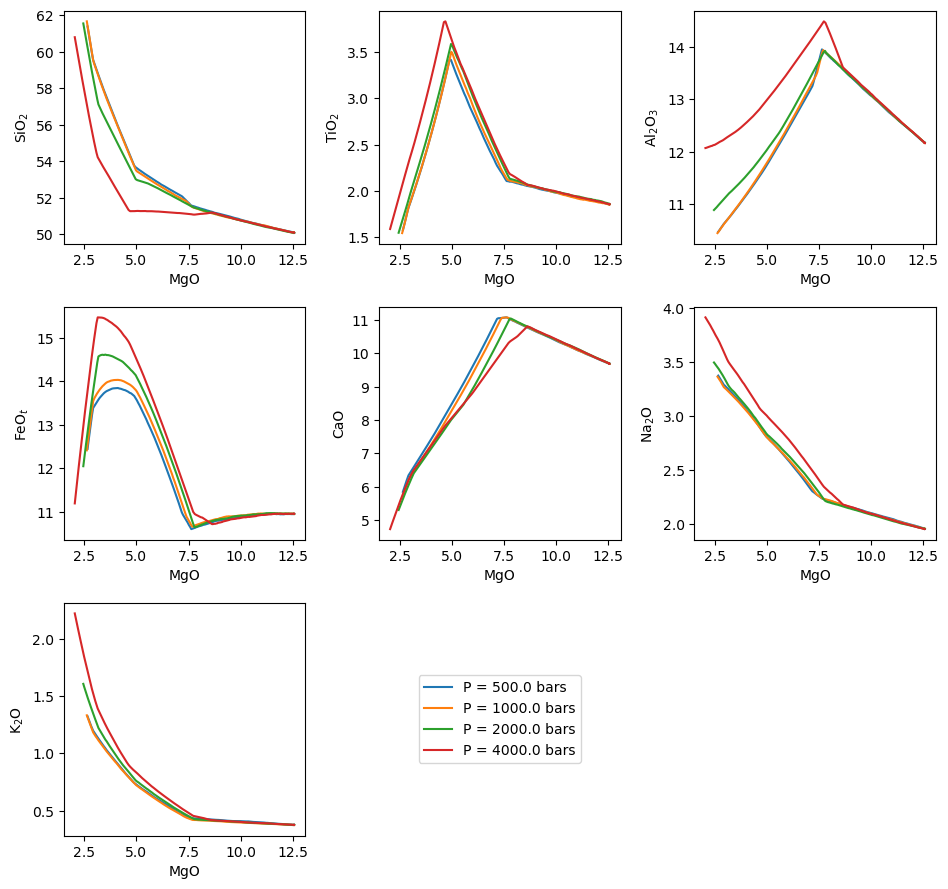

In [8]:
ptt.harker(frac_green)

(<Figure size 500x350 with 1 Axes>,
 ([<Figure size 500x350 with 1 Axes>,
   <Figure size 500x350 with 1 Axes>,
   <Figure size 500x350 with 1 Axes>,
   <Figure size 500x350 with 1 Axes>],
  [<Axes: title={'center': 'P = 500.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>,
   <Axes: title={'center': 'P = 1000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>,
   <Axes: title={'center': 'P = 2000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>,
   <Axes: title={'center': 'P = 4000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>]))

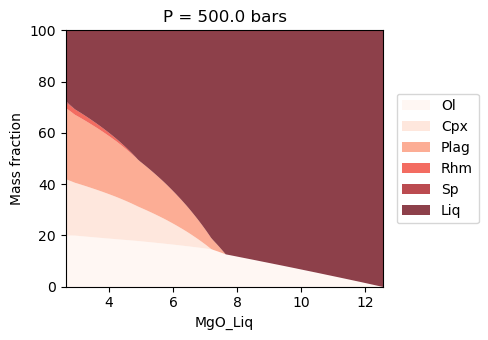

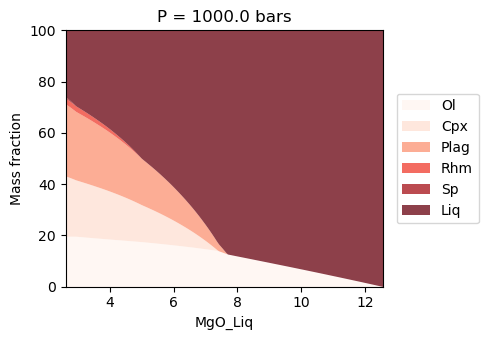

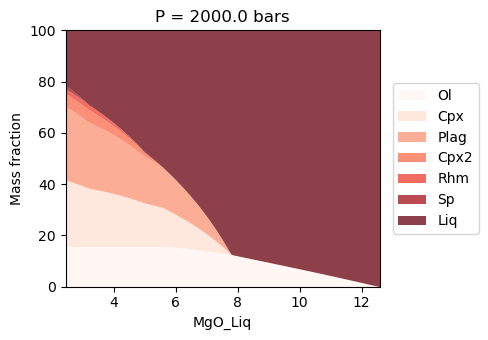

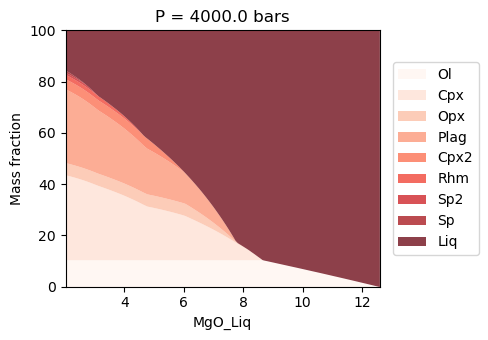

In [9]:
ptt.phase_plot(Results = frac_green, x_axis = "MgO_Liq")

In [10]:
frac_melts = ptt.isobaric_crystallisation(Model = "MELTSv1.0.2",
                                        bulk = shield,
                                        find_liquidus=True,
                                        Frac_solid = True,
                                        dt_C = 2,
                                        T_end_C = 1000,
                                        P_bar = [500,1000,2000,4000],
                                        fO2_buffer="FMQ",
                                        label = "P_bar")

multi_path_v2: timeout not specified, using the platform default of 60s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/4 [00:00<?, ?it/s]

multi_path_v2: 4/4 completed, 0/4 returned partial results after a crash, 0/4 returned partial results after timing out, 0/4 returned no results (no retry by default -- see max_retries).


(<Figure size 960x900 with 9 Axes>,
 array([[<Axes: xlabel='MgO', ylabel='SiO$_2$'>,
         <Axes: xlabel='MgO', ylabel='TiO$_2$'>,
         <Axes: xlabel='MgO', ylabel='Al$_2$O$_3$'>],
        [<Axes: xlabel='MgO', ylabel='FeO$_t$'>,
         <Axes: xlabel='MgO', ylabel='CaO'>,
         <Axes: xlabel='MgO', ylabel='Na$_2$O'>],
        [<Axes: xlabel='MgO', ylabel='K$_2$O'>, <Axes: >, <Axes: >]],
       dtype=object))

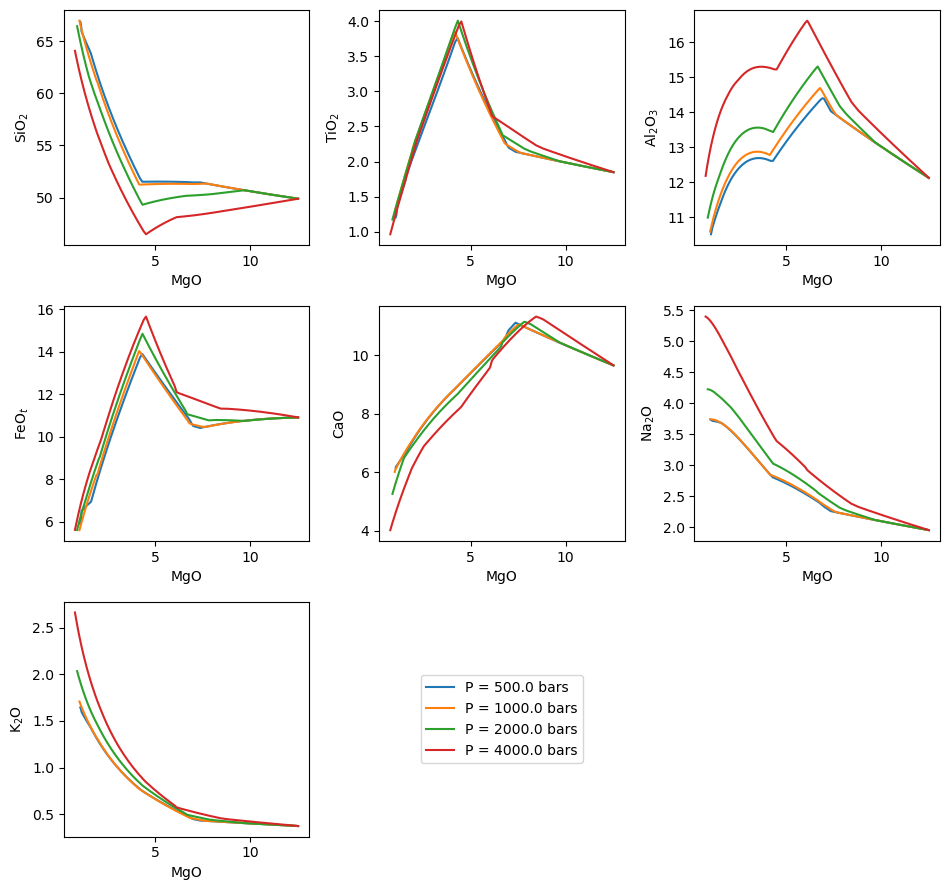

In [11]:
ptt.harker(frac_melts)

(<Figure size 500x350 with 1 Axes>,
 ([<Figure size 500x350 with 1 Axes>,
   <Figure size 500x350 with 1 Axes>,
   <Figure size 500x350 with 1 Axes>,
   <Figure size 500x350 with 1 Axes>],
  [<Axes: title={'center': 'P = 500.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>,
   <Axes: title={'center': 'P = 1000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>,
   <Axes: title={'center': 'P = 2000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>,
   <Axes: title={'center': 'P = 4000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>]))

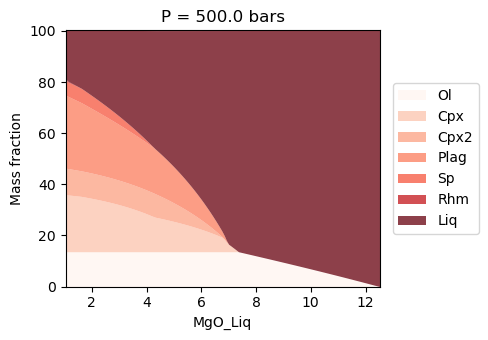

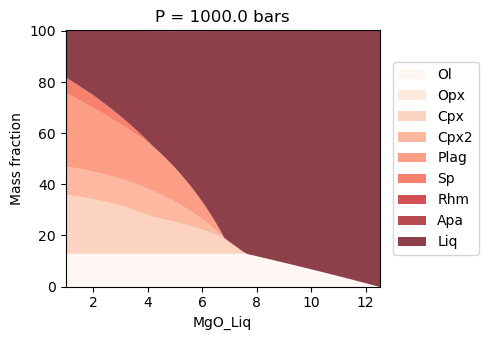

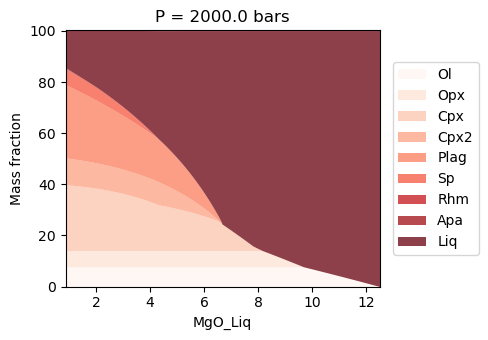

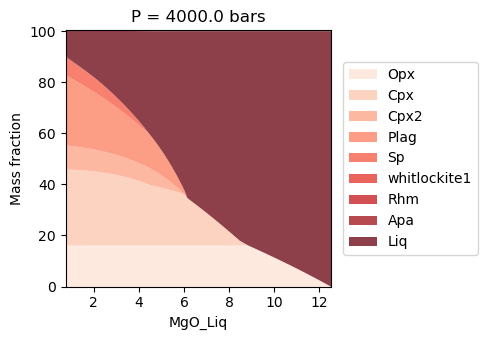

In [12]:
ptt.phase_plot(Results = frac_melts, x_axis = "MgO_Liq")

Compare the models, look at the influence of pressure on phase stability!

# Part 2 - Phase Diagrams

One of the interesting things about Hualalai is the abundance of crustal xenoliths found in some of the post-shield lava flows. I've been working with a few students on trying to understand the origin of these xenoliths, and what they tell us about the temporal and spatial evolution of Hualalai's magmatic system. One of the first things we needed to determine was, for each xenolith, whether it originated from a magmatic system that was part of Hualalai's shield or post-shield stage.

For the gabbroic xenoliths various approaches have been proposed (there will be information about this on my AGU poster on the topic), including radiogenic isotope compositions, feldspar K2O contents, and mineralogical signatures (specifically the presence or absence of orthopyroxene). An EDS map of one of the gabbros is shown below:

![EDS map and plagioclase data from Hualalai](Hualalai.png)

However, this map, and associated plagioclase data, reveals some confusing signatures. The sample is clearly an olivine and orthopyroxene cumulate, with intercumulus growth of plagioclase and clinopyroxene, and would traditionally be interpreted as a shield-stage cumulate as a result (due to the presence of orthopyroxene). However, the plagioclase data reveals elevated K2O contents, consistent with crystallization from an alkali-rich basalt. To try and address this apparent discrepancy I've asked students to investigate the role of melt composition, pressure, and other parameters on orthopyroxene stability in shield stage and post-shield stage magmas from Hualalai. Let's recreate some of these calculations below!

Within PetThermoTools there is a function called `phaseDiagram_calc` which can be used to create a P-T grid of phase abundance, composition, and thermodynamic properties. Use the cells below to create phase diagrams between 1400 and 1000 degrees Celsuis and 500 and 10000 bars for both the shield and post-shield basalts above.

In [13]:
help(ptt.phaseDiagram_calc)

Help on function phaseDiagram_calc in module petthermotools.PhaseDiagrams:

phaseDiagram_calc(cores=None, Model=None, bulk=None, T_C=None, P_bar=None, T_min_C=None, T_max_C=None, T_num=None, P_min_bar=None, P_max_bar=None, P_num=None, Fe3Fet_Liq=None, H2O_Liq=None, CO2_Liq=None, Fe3Fet_init=None, H2O_init=None, CO2_init=None, fO2_buffer=None, fO2_offset=None, i_max=15, grid=True, refine=None, Suppress=['rutile', 'tridymite'], quiet_engine=True)
    Calculates a Phase Diagram (P-T grid) for a given bulk composition using MELTS or MAGEMinCalc 
    via parallel processing.
    
    The function handles setting up the T-P grid, distributing calculations across multiple 
    cores, and iteratively re-attempting failed points up to a maximum number of attempts (`i_max`).
    
    Parameters:
    -----------
    cores : int, optional
        The number of CPU cores for parallel processing. Defaults to all available cores.
    Model : str, optional, default "MELTSv1.0.2"
        The name of th

In [14]:
PD_shield = ptt.phaseDiagram_calc(Model = "Green2025", 
                                bulk = shield,
                                T_C = np.linspace(1000,1400,25),
                                P_bar = np.linspace(500,10000,25),
                                Fe3Fet_init=0.18,
                                refine = 2)

Computing 156 points... 100%|████████████████████████████| Time: 0:00:30
Computing 156 points... 100%|████████████████████████████| Time: 0:00:30
Computing 157 points... 100%|████████████████████████████| Time: 0:00:30
Computing 156 points... 100%|████████████████████████████| Time: 0:00:31
Performing another 393 calculations with interpolation used to calculate 1383 points.
Computing 98 points... 100%|█████████████████████████████| Time: 0:00:15
Computing 98 points... 100%|█████████████████████████████| Time: 0:00:15
Computing 99 points... 100%|█████████████████████████████| Time: 0:00:18
Computing 98 points... 100%|█████████████████████████████| Time: 0:00:19
Performing another 817 calculations with interpolation used to calculate 6191 points.
Computing 204 points... 100%|████████████████████████████| Time: 0:00:32
Computing 204 points... 100%|████████████████████████████| Time: 0:00:34
Computing 205 points... 100%|████████████████████████████| Time: 0:00:38
Computing 204 points... 1

In [15]:
PD_postshield = ptt.phaseDiagram_calc(Model = "Green2025", 
                                bulk = postshield,
                                T_C = np.linspace(1000,1400,25),
                                P_bar = np.linspace(500,10000,25),
                                Fe3Fet_init=0.18,
                                refine = 2)

Computing 156 points... 100%|████████████████████████████| Time: 0:00:30
Computing 157 points... 100%|████████████████████████████| Time: 0:00:30
Computing 156 points... 100%|████████████████████████████| Time: 0:00:31
Computing 156 points... 100%|████████████████████████████| Time: 0:00:31
Performing another 373 calculations with interpolation used to calculate 1403 points.
Computing 93 points... 100%|█████████████████████████████| Time: 0:00:13
Computing 93 points... 100%|█████████████████████████████| Time: 0:00:14
Computing 94 points... 100%|█████████████████████████████| Time: 0:00:15
Computing 93 points... 100%|█████████████████████████████| Time: 0:00:15
Performing another 820 calculations with interpolation used to calculate 6188 points.
Computing 205 points... 100%|████████████████████████████| Time: 0:00:30
Computing 205 points... 100%|████████████████████████████| Time: 0:00:33
Computing 205 points... 100%|████████████████████████████| Time: 0:00:33
Computing 205 points... 1

As before, there are in-built plotting functions that can be used to visualize the results of these calculations. For individual phase diagrams we can plot them using `ptt.plot_phaseDiagram` and we can easily compare multiple phase diagrams via `ptt.plot_phaseDiagram_multi`.

(<Figure size 1200x1200 with 3 Axes>,
 [<Axes: title={'center': 'Shield'}, xlabel='Temperature ($\\degree$C)', ylabel='Pressure (bar)'>,
  <Axes: title={'center': 'Post-shield'}, xlabel='Temperature ($\\degree$C)', ylabel='Pressure (bar)'>,
  <Axes: >])

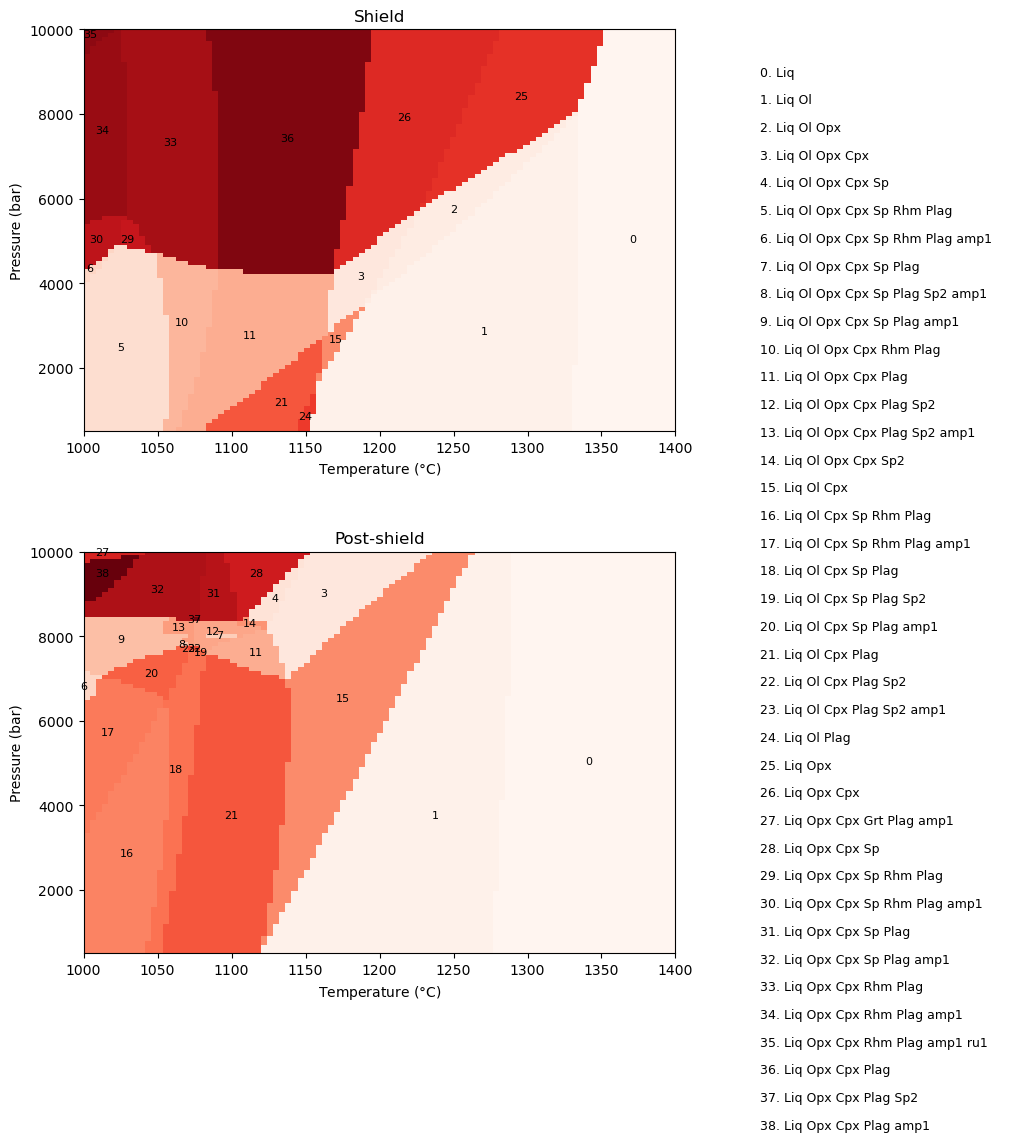

In [16]:
ptt.plot_phaseDiagram_multi({"Shield": PD_shield, "Post-shield": PD_postshield})

If we are interested in the stability of orthopyroxene we could also examine that in more detail. Penny designed a function called `ptt.make_grid_variables_from_phase_diagram` that allows us to extract the phase diagram results into a grid format that allows for easy plotting.

In [17]:
X_shield, Y_shield, Z_shield = ptt.make_grid_variables_from_phase_diagram(
    Results = PD_shield,
    x_col = "T_C",
    y_col = "P_bar",
)

opx_shield = Z_shield["mass_g_Opx"]

X_postshield, Y_postshield, Z_postshield = ptt.make_grid_variables_from_phase_diagram(
    Results = PD_postshield,
    x_col = "T_C",
    y_col = "P_bar",
)

opx_postshield = Z_postshield["mass_g_Opx"]

We can then make use of `contourf` to plot these results:

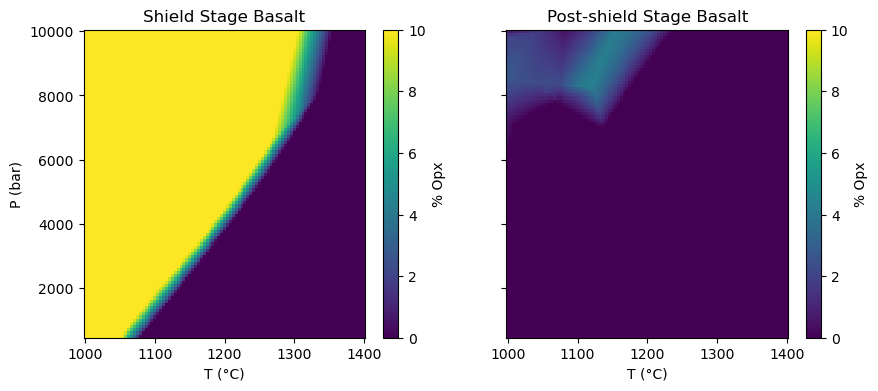

In [18]:
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 4), sharex=True, sharey=True
)

# ------------------------------------------------
# Panel 1: Opx in Green
pcm1 = ax1.pcolormesh(
    X_shield, Y_shield, Z_shield["mass_g_Opx"],
    shading="auto",
    cmap="viridis", vmin=0, vmax=10,
)
ax1.set_title("Shield Stage Basalt")
ax1.set_xlabel("T (°C)")
ax1.set_ylabel("P (bar)")
fig.colorbar(pcm1, ax=ax1, label="% Opx")

# ------------------------------------------------
# Panel 2: Opx in pMELTS

pcm2 = ax2.pcolormesh(
    X_postshield, Y_postshield, np.nan_to_num(Z_postshield["mass_g_Opx"]),
    shading="auto",
    cmap="viridis", vmin=0, vmax=10,
)
ax2.set_title("Post-shield Stage Basalt")
ax2.set_xlabel("T (°C)")
fig.colorbar(pcm2, ax=ax2, label="% Opx")


Have a go running the same calcualtions with the rhyolite-MELTS v1.0.2 models. What differences do you see?

# Part 3 - Computational speed ups with nGibbs

nGibbs is a neural network machine learning model (https://github.com/benjthyer/nGibbs) that is trained on rhyolite-MELTS 1.0.2 and rhyolite-MELTS 1.2.0. 

## Why use an emulator instead of "the real deal"? 

nGibbs is 100s to 1000s of times as fast as MELTS for large jobs. Some problems are much easier to solve when the calculations are fast. For instance, Let's say you have a cumulate rock and you want to identify the composition of its parent magma and the conditions of its crystallization. There's a lot of variables that you may need to explore: Pressure, temperature, oxygen fugacity, water content, SiO2, CaO, Al2O3, CO2, etc etc... You could use a Monte Carlo Markov chain with all of these degrees of freedom, but you would need a very fast model for this to be feasible! This is where nGibbs comes in. Surrogate models like nGibbs are also used for making geodynamic simulations more realistic. A fast model like nGibbs is also useful for broad searches of compositions and conditions in early phases of research in preparation for full thermodynamic calculations.

Although not implemented in PetThermoTools, nGibbs also emulates HeFESTo thermodynamic modelling for subsolidus phase equilibria of the mantle (https://kgblab.epss.ucla.edu/project/hefesto/). Releases coming soon will support pMELTS as well! 

This release is a bit of a preview, so please send Ben comments, notice of bugs, suggestions, collaborations, and questions! If nGibbs isn't quite there yet for your specific use, we may be able to train a new model for it. (bthyer@caltech.edu)

One of the coolest things about nGibbs is that it can be used in PetThermoTools very similarly to the other MELTS models, so it should be easy to integrate into your workflows. 

For instance, instead of calling 

```
equil = ptt.equilibrate_multi(Model = "MELTSv1.2.0",
                            bulk = LL8,
                            P_bar = Sat_PT['P_bar'].values,
                            T_C = Sat_PT['T_Liq_C'].values)
```

Just put an "n" in front of the Model name: "nMELTSv1.2.0"! 
And optionally add "NoProp" afterwards if you can skip the calculations of the thermodynamic properties (this is useful if you are only interested in phase equilibria: It saves a lot of time.)

This runs the same calculation on the nGibbs emulator of rhyolite-MELTS 1.2.0!

```
equil = ptt.equilibrate_multi(Model = "nMELTSv1.2.0", # or Model = "nMELTSv1.2.0NoProp"
                            bulk = LL8,
                            P_bar = Sat_PT['P_bar'].values,
                            T_C = Sat_PT['T_Liq_C'].values)
```


Thyer, B. J. (2026). nGibbs (Version 0.1.0b4). https://doi.org/10.5281/zenodo.20766922

In your own time, use the code below to create a phase diagram animation with nGibbs to investigate how changing parameters (initially this is designed to investigate variations in fO2) on phase stability:

In [19]:
base_kwargs = dict(Model = "nMELTSv1.0.2NoProp",
                                bulk = shield,
                                T_C = np.linspace(1100,1600,20),
                                P_bar = np.linspace(250,5000,20),
)
print(f"nGibbs animated Phase Diagram calculation")

frame_kwargs = {'fO2_offset': np.linspace(-5,5,11)}

ani = ptt.animate_phaseDiagram(base_kwargs, frame_kwargs, P_units="bar", T_units="C",
                         label=True, colormap=None, interval=500)
plt.close() # Don't show static plot in notebook
ani.save(filename="phase_diagram.gif", writer="pillow")
from IPython.display import HTML
HTML(ani.to_jshtml())

nGibbs animated Phase Diagram calculation
